# Supplementary fold-wise confusion-matrix and ROC panels

This notebook is a read-only analysis of already saved fold results. It does not load checkpoints, run model inference, or modify existing files. It creates raw and row-normalized five-fold confusion-matrix panels and five-panel test ROC figures (A-E) for the finalized Proposed model and EfficientNet-B0 when exact saved sources are available.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc

warnings.filterwarnings('ignore', category=UserWarning)
PROJECT_ROOT = Path('/media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM')
RESULTS_DIR = PROJECT_ROOT / 'Results'
OUTPUT_DIR = RESULTS_DIR / 'Analysis' / 'Supplementary_Confusion_Matrices'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS = tuple(range(1, 6))
EXPECTED_TEST_SIZE = 719
CLASS_NAMES = ['CN', 'SMC', 'EMCI', 'MCI', 'LMCI', 'AD']
SOURCE_CLASS_ORDER = ['AD', 'CN', 'EMCI', 'LMCI', 'MCI', 'SMC']
CLASS_COLORS = {'CN': '#1f77b4', 'SMC': '#ff7f0e', 'EMCI': '#2ca02c', 'MCI': '#d62728', 'LMCI': '#9467bd', 'AD': '#8c564b'}
PANEL_LABELS = dict(zip(FOLDS, 'ABCDE'))
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})
print('Active Results directory:', RESULTS_DIR)
print('New analysis output directory:', OUTPUT_DIR)
print('Fixed class order:', CLASS_NAMES)

Active Results directory: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results
New analysis output directory: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices
Fixed class order: ['CN', 'SMC', 'EMCI', 'MCI', 'LMCI', 'AD']


## Phase 1 — inventory of saved fold sources

The inventory is deliberately restricted to the active `Results/` directory. Classification reports alone are never used to estimate a confusion matrix.

In [2]:
MODEL_SPECS = {
    'Proposed': {
        'root': RESULTS_DIR / 'Proposed_Model',
        'prediction_template': 'fold_{fold}/probs_fold_{fold}.csv',
        'classification_report_template': 'fold_{fold}/classification_report_fold_{fold}.csv',
        'roc_template': 'fold_{fold}/roc_data_fold_{fold}.csv',
    },
    'EfficientNet-B0': {
        'root': RESULTS_DIR / 'Baselines' / '3DEfficientNet_ImageID_5Fold',
        'prediction_template': 'fold_{fold}/test_predictions.csv',
        'confusion_template': 'fold_{fold}/confusion_matrix_test.csv',
        'classification_report_template': 'fold_{fold}/classification_report_test.csv',
        'roc_template': 'fold_{fold}/roc_test_data.csv',
    },
}

def path_for(spec, key, fold):
    template = spec.get(key)
    return spec['root'] / template.format(fold=fold) if template else None

def first_matching(folder, terms):
    if not folder.exists():
        return None
    files = sorted(p for p in folder.iterdir() if p.is_file())
    for p in files:
        name = p.name.lower()
        if all(term in name for term in terms):
            return p
    return None

print('SAVED-RESULT INVENTORY')
for model_name, spec in MODEL_SPECS.items():
    print(f'\nMODEL: {model_name}')
    for fold in FOLDS:
        fold_dir = spec['root'] / f'fold_{fold}'
        pred = path_for(spec, 'prediction_template', fold)
        cm = path_for(spec, 'confusion_template', fold)
        report = path_for(spec, 'classification_report_template', fold)
        roc_path = path_for(spec, 'roc_template', fold)
        if report is None or not report.exists():
            report = first_matching(fold_dir, ['classification', 'report'])
        print(f'Fold {fold}:')
        print('  prediction/probability source:', pred if pred and pred.exists() else 'NOT FOUND')
        print('  confusion matrix file:', cm if cm and cm.exists() else 'NOT FOUND')
        print('  classification report:', report if report and report.exists() else 'NOT FOUND')
        print('  ROC data:', roc_path if roc_path and roc_path.exists() else 'NOT FOUND')
        exact = bool((cm and cm.exists()) or (pred and pred.exists()))
        print('  exact CM generation possible:', 'YES' if exact else 'NO')

print('\nOnly exact labels/probabilities or exact saved 6x6 matrices will be used; reports alone are insufficient.')

SAVED-RESULT INVENTORY

MODEL: Proposed
Fold 1:
  prediction/probability source: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Proposed_Model/fold_1/probs_fold_1.csv
  confusion matrix file: NOT FOUND
  classification report: NOT FOUND
  ROC data: NOT FOUND
  exact CM generation possible: YES
Fold 2:
  prediction/probability source: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Proposed_Model/fold_2/probs_fold_2.csv
  confusion matrix file: NOT FOUND
  classification report: NOT FOUND
  ROC data: NOT FOUND
  exact CM generation possible: YES
Fold 3:
  prediction/probability source: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Proposed_Model/fold_3/probs_fold_3.csv
  confusion matrix file: NOT FOUND
  classification report: NOT FOUND
  ROC data: NOT FOUND
  exact CM generation possible: YES
Fold 4:
  prediction/probability source: /media/faizaan/4TB/1_DATA_PR

## Phase 2 — exact matrices, mapping verification, and validation

In [3]:
def reorder_matrix(frame, source_order):
    frame = frame.copy()
    frame.index = frame.index.astype(str)
    frame.columns = frame.columns.astype(str)
    missing_rows = set(source_order) - set(frame.index)
    missing_cols = set(source_order) - set(frame.columns)
    if missing_rows or missing_cols:
        raise ValueError(f'Matrix labels do not match source order; missing rows={missing_rows}, columns={missing_cols}')
    frame = frame.loc[source_order, source_order]
    return frame.loc[CLASS_NAMES, CLASS_NAMES].astype(float)

def load_proposed_fold(fold):
    path = path_for(MODEL_SPECS['Proposed'], 'prediction_template', fold)
    df = pd.read_csv(path)
    prob_cols = [f'prob_{name}' for name in SOURCE_CLASS_ORDER]
    required = set(prob_cols + ['true'])
    if not required.issubset(df.columns):
        raise ValueError(f'Proposed fold {fold} lacks required exact columns: {sorted(required - set(df.columns))}')
    y_true_ids = df['true'].astype(int).to_numpy()
    if not np.isin(y_true_ids, np.arange(len(SOURCE_CLASS_ORDER))).all():
        raise ValueError(f'Unexpected Proposed numeric labels in fold {fold}')
    probs = df[prob_cols].to_numpy(dtype=float)
    y_pred_ids = probs.argmax(axis=1)
    cm_source = confusion_matrix(y_true_ids, y_pred_ids, labels=np.arange(len(SOURCE_CLASS_ORDER)))
    cm = pd.DataFrame(cm_source, index=SOURCE_CLASS_ORDER, columns=SOURCE_CLASS_ORDER)
    return {'cm': reorder_matrix(cm, SOURCE_CLASS_ORDER), 'probs': probs, 'true_ids': y_true_ids, 'source': str(path), 'source_kind': 'saved y_true + saved probabilities'}

def load_efficientnet_fold(fold):
    cm_path = path_for(MODEL_SPECS['EfficientNet-B0'], 'confusion_template', fold)
    pred_path = path_for(MODEL_SPECS['EfficientNet-B0'], 'prediction_template', fold)
    if not cm_path.exists():
        raise FileNotFoundError(f'Exact EfficientNet confusion matrix missing for fold {fold}')
    cm_raw = pd.read_csv(cm_path, index_col=0)
    cm_raw = cm_raw.loc[:, ~cm_raw.columns.astype(str).str.startswith('Unnamed')]
    return {'cm': reorder_matrix(cm_raw, SOURCE_CLASS_ORDER), 'prediction_path': str(pred_path), 'source': str(cm_path), 'source_kind': 'saved exact 6x6 confusion matrix'}

def report_supports(model_name, fold):
    spec = MODEL_SPECS[model_name]
    report_path = path_for(spec, 'classification_report_template', fold)
    if not report_path or not report_path.exists():
        return None, None
    report = pd.read_csv(report_path)
    label_col = 'class_or_average' if 'class_or_average' in report.columns else report.columns[0]
    support = {}
    for _, row in report.iterrows():
        label = str(row[label_col])
        if label in CLASS_NAMES and pd.notna(row.get('support')):
            support[label] = int(row['support'])
    return support, report_path

fold_data = {'Proposed': {}, 'EfficientNet-B0': {}}
for fold in FOLDS:
    fold_data['Proposed'][fold] = load_proposed_fold(fold)
    fold_data['EfficientNet-B0'][fold] = load_efficientnet_fold(fold)

# The Proposed probability columns explicitly verify the numeric encoding used by its saved true labels.
proposed_support_by_id = []
for fold in FOLDS:
    proposed_support_by_id.append(pd.Series(fold_data['Proposed'][fold]['true_ids']).value_counts().reindex(range(6), fill_value=0).to_numpy())
proposed_support_by_id = np.asarray(proposed_support_by_id)
expected_support = np.asarray([81, 186, 219, 114, 92, 27])
if not np.all(proposed_support_by_id == expected_support):
    raise AssertionError(f'Proposed support/mapping verification failed: {proposed_support_by_id}')
print('Verified Proposed numeric mapping from named probability columns and fixed supports:')
print(dict(enumerate(SOURCE_CLASS_ORDER)))
print('Verified support by Proposed numeric ID:', dict(zip(SOURCE_CLASS_ORDER, expected_support)))

all_support_vectors = []
for model_name, folds in fold_data.items():
    print(f'\nVALIDATION: {model_name}')
    for fold, data in folds.items():
        cm = data['cm'].to_numpy(dtype=int)
        if cm.shape != (6, 6):
            raise AssertionError(f'{model_name} fold {fold} matrix shape is {cm.shape}, expected (6, 6)')
        if int(cm.sum()) != EXPECTED_TEST_SIZE:
            raise AssertionError(f'{model_name} fold {fold} matrix sum {cm.sum()} != {EXPECTED_TEST_SIZE}')
        support = cm.sum(axis=1)
        report_support, report_path = report_supports(model_name, fold)
        if report_support:
            report_vector = np.asarray([report_support.get(name, -1) for name in CLASS_NAMES])
            if not np.array_equal(support, report_vector):
                raise AssertionError(f'{model_name} fold {fold} row support {support} != report {report_vector}')
            report_status = 'matches saved classification report'
        else:
            report_status = 'no fold report available; exact labels/matrix used'
        normalized = np.divide(cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] != 0)
        if not np.allclose(normalized.sum(axis=1)[support > 0], 1.0):
            raise AssertionError(f'{model_name} fold {fold} normalized rows do not sum to 1')
        data['normalized'] = pd.DataFrame(normalized, index=CLASS_NAMES, columns=CLASS_NAMES)
        data['support'] = support
        all_support_vectors.append((model_name, fold, support.copy()))
        print(f'Fold {fold}: cm.sum()={int(cm.sum())}; row support={support.tolist()}; {report_status}')

for model_name in fold_data:
    vectors = [v for m, _, v in all_support_vectors if m == model_name]
    if not all(np.array_equal(vectors[0], v) for v in vectors[1:]):
        raise AssertionError(f'{model_name} fixed-test support differs across folds')
    print(f'{model_name} same fixed test cohort support across folds:', vectors[0].tolist())

Verified Proposed numeric mapping from named probability columns and fixed supports:
{0: 'AD', 1: 'CN', 2: 'EMCI', 3: 'LMCI', 4: 'MCI', 5: 'SMC'}
Verified support by Proposed numeric ID: {'AD': np.int64(81), 'CN': np.int64(186), 'EMCI': np.int64(219), 'LMCI': np.int64(114), 'MCI': np.int64(92), 'SMC': np.int64(27)}

VALIDATION: Proposed
Fold 1: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81]; no fold report available; exact labels/matrix used
Fold 2: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81]; no fold report available; exact labels/matrix used
Fold 3: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81]; no fold report available; exact labels/matrix used
Fold 4: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81]; no fold report available; exact labels/matrix used
Fold 5: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81]; no fold report available; exact labels/matrix used

VALIDATION: EfficientNet-B0
Fold 1: cm.sum()=719; row support=[186, 27, 219, 92, 114, 81];

## Phase 3 — save exact matrices and generate five-panel confusion-matrix figures

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ConfusionMatrices_Raw.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ConfusionMatrices_Raw.pdf


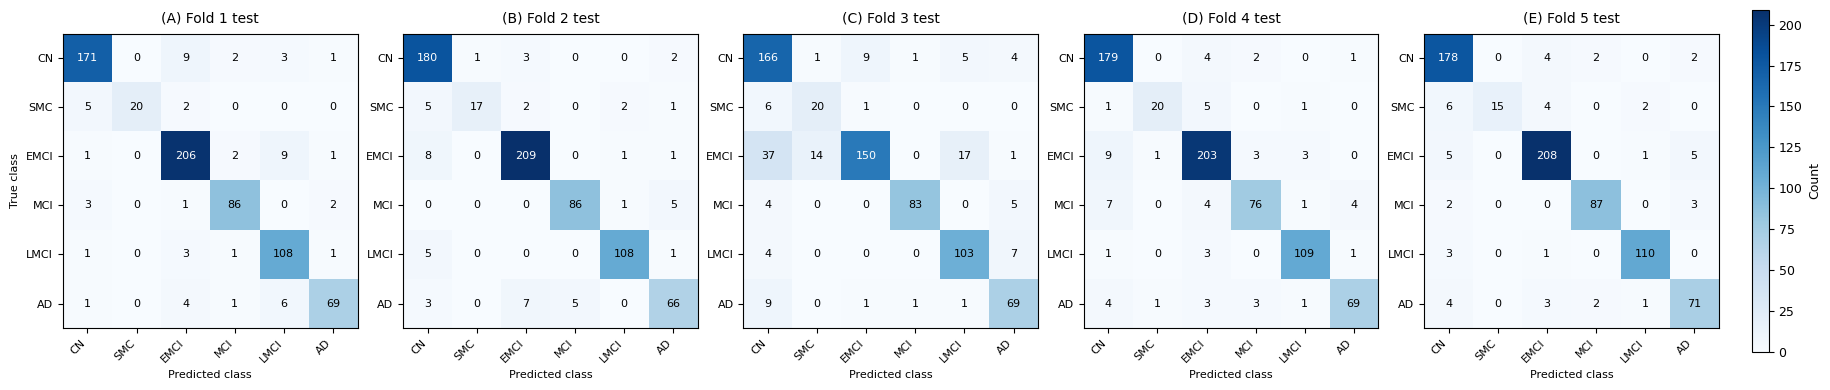

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ConfusionMatrices_Normalized.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ConfusionMatrices_Normalized.pdf


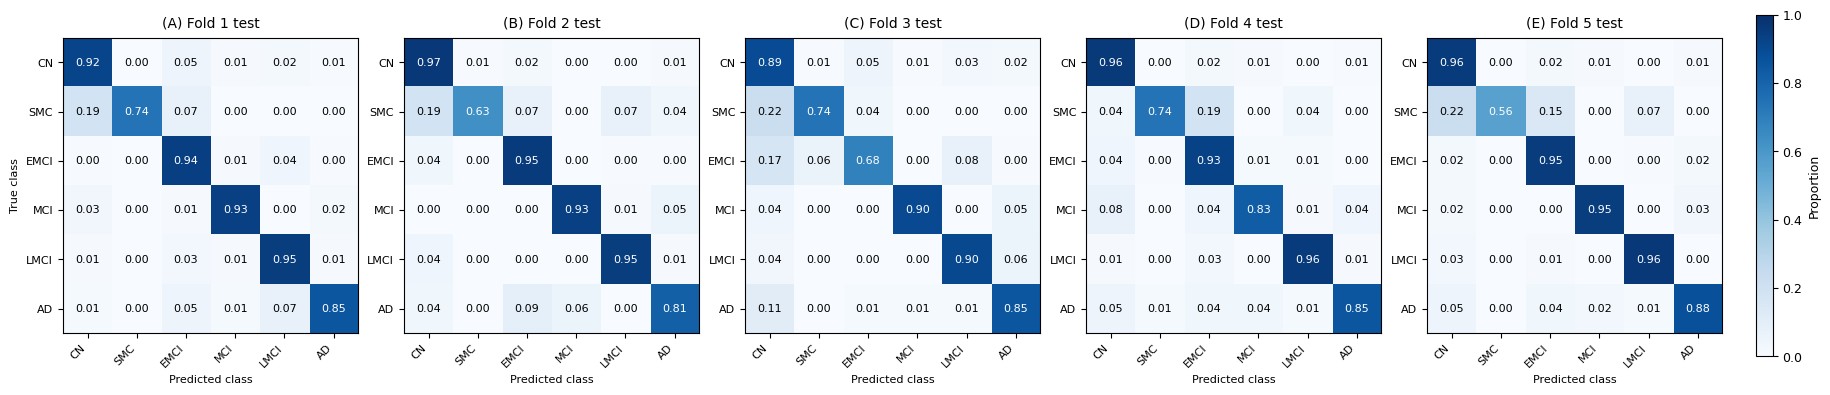

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ConfusionMatrices_Raw.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ConfusionMatrices_Raw.pdf


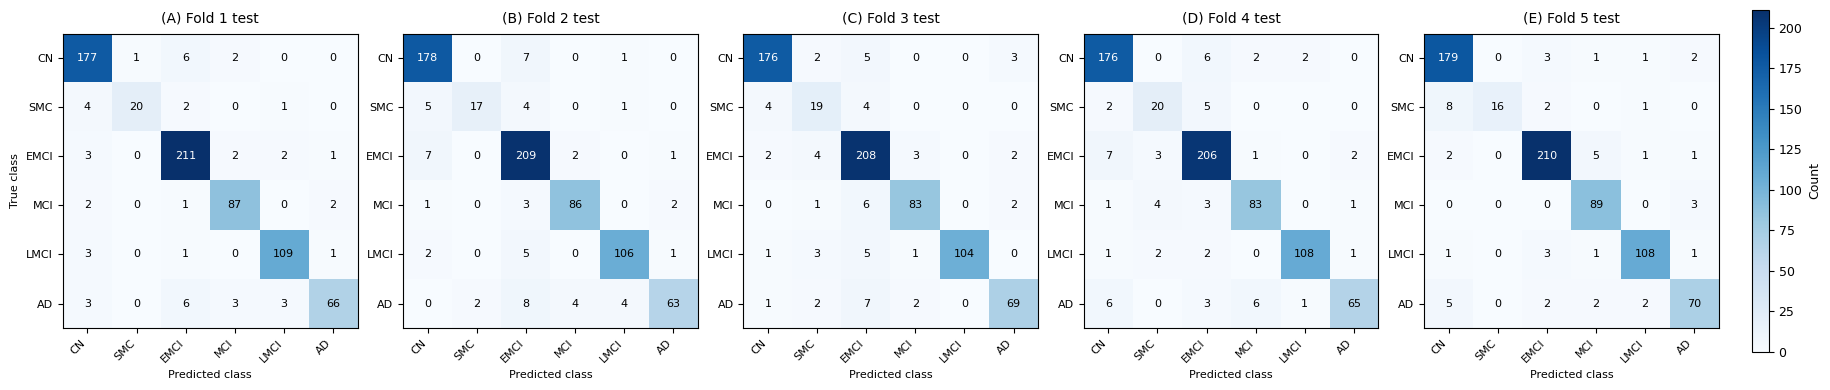

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ConfusionMatrices_Normalized.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ConfusionMatrices_Normalized.pdf


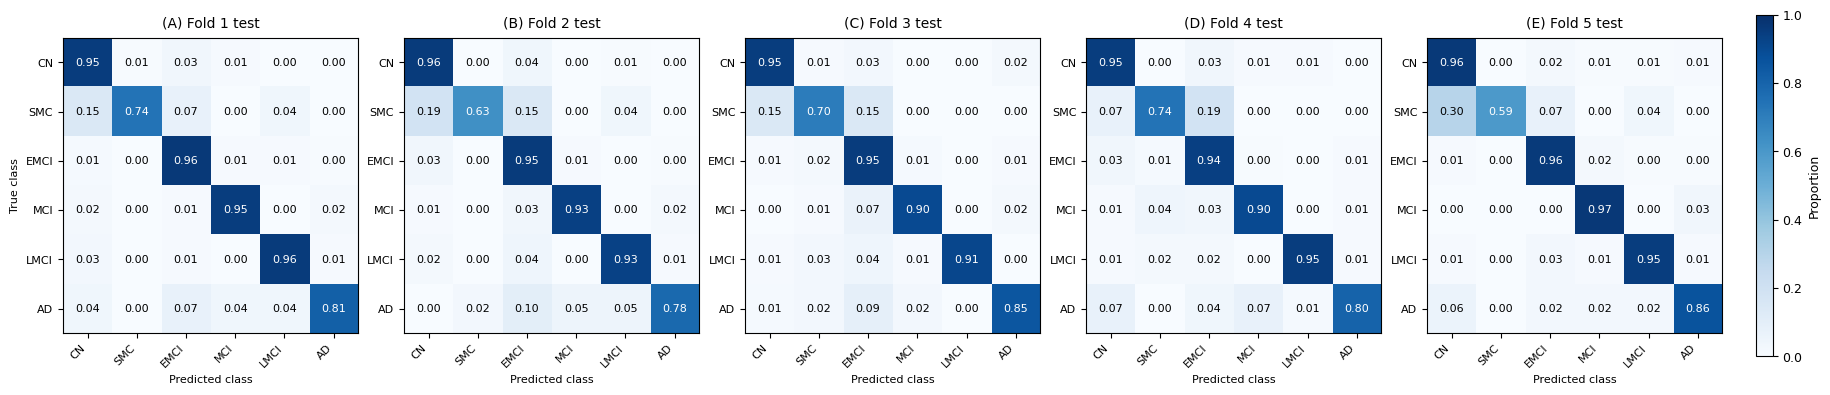

In [4]:
def save_matrices_and_plot(model_name, file_prefix):
    for fold in FOLDS:
        data = fold_data[model_name][fold]
        data['cm'].round().astype(int).to_csv(OUTPUT_DIR / f'{file_prefix}_Fold{fold}_CM_raw.csv')
        data['normalized'].to_csv(OUTPUT_DIR / f'{file_prefix}_Fold{fold}_CM_normalized.csv')
    raw_max = max(int(fold_data[model_name][fold]['cm'].to_numpy().max()) for fold in FOLDS)
    for normalized, suffix, label_fmt in [(False, 'Raw', lambda x: f'{int(round(x))}'), (True, 'Normalized', lambda x: f'{x:.2f}')]:
        fig, axes = plt.subplots(1, 5, figsize=(18.2, 4.25), constrained_layout=True)
        axes = np.atleast_1d(axes)
        image = None
        for ax, fold in zip(axes, FOLDS):
            matrix = fold_data[model_name][fold]['normalized' if normalized else 'cm'].to_numpy(dtype=float)
            image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1 if normalized else raw_max, interpolation='nearest', aspect='equal')
            for i in range(6):
                for j in range(6):
                    value = matrix[i, j]
                    text_color = 'white' if value > (0.55 if normalized else raw_max * 0.55) else 'black'
                    ax.text(j, i, label_fmt(value), ha='center', va='center', fontsize=8, color=text_color)
            ax.set_xticks(range(6), CLASS_NAMES, rotation=45, ha='right', fontsize=8)
            ax.set_yticks(range(6), CLASS_NAMES, fontsize=8)
            ax.set_xlabel('Predicted class', fontsize=8)
            ax.set_title(f"({PANEL_LABELS[fold]}) Fold {fold} test", fontsize=10, pad=8)
        axes[0].set_ylabel('True class', fontsize=8)
        fig.colorbar(image, ax=axes.tolist(), shrink=0.82, pad=0.02, label='Proportion' if normalized else 'Count')
        png = OUTPUT_DIR / f'{file_prefix}_FiveFold_ConfusionMatrices_{suffix}.png'
        pdf = OUTPUT_DIR / f'{file_prefix}_FiveFold_ConfusionMatrices_{suffix}.pdf'
        fig.savefig(png, dpi=600, bbox_inches='tight')
        fig.savefig(pdf, bbox_inches='tight')
        print('Saved:', png)
        print('Saved:', pdf)
        display(fig)
        plt.close(fig)

save_matrices_and_plot('Proposed', 'Proposed')
save_matrices_and_plot('EfficientNet-B0', 'EfficientNetB0')

## Phase 4 — fold-wise test ROC panels (A-E)

ROC curves are read from saved fold probability/ROC-data files. No model is loaded and no inference is performed.

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ROC_Test_Panels.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_FiveFold_ROC_Test_Panels.pdf
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_Foldwise_ROC_AUC.csv


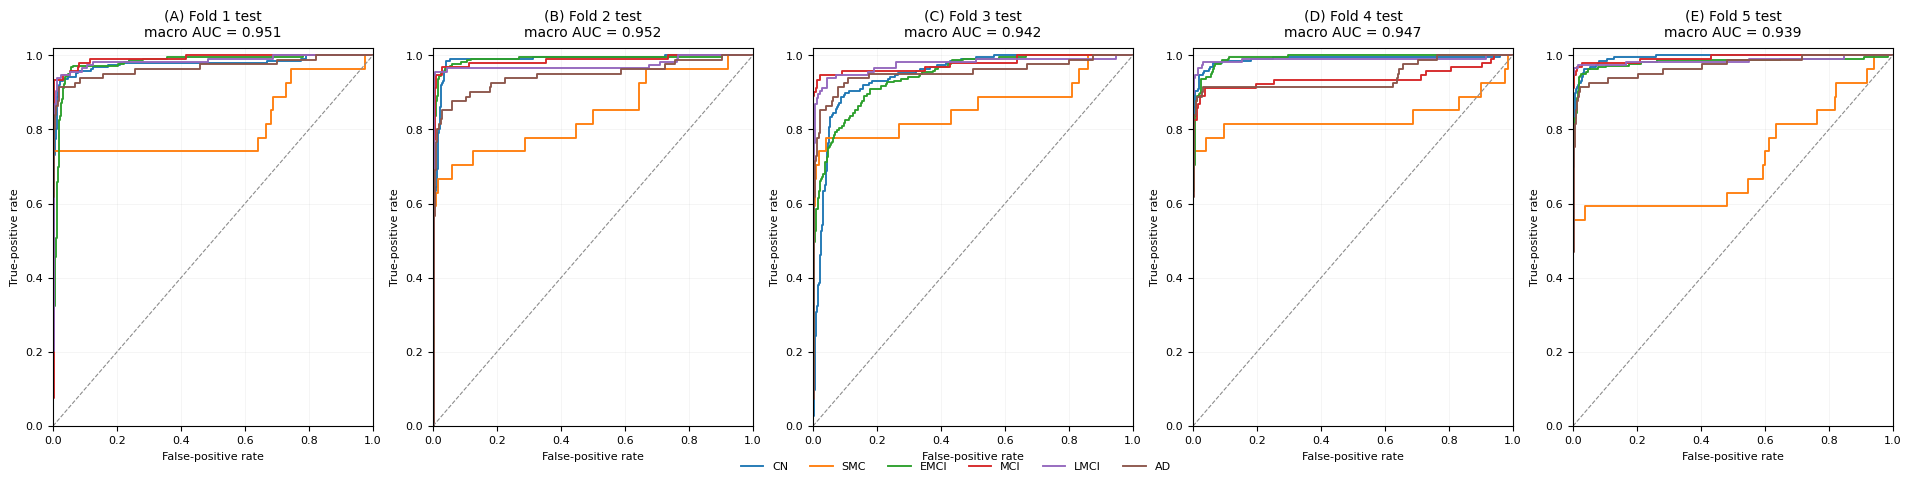

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ROC_Test_Panels.png
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_FiveFold_ROC_Test_Panels.pdf
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_Foldwise_ROC_AUC.csv


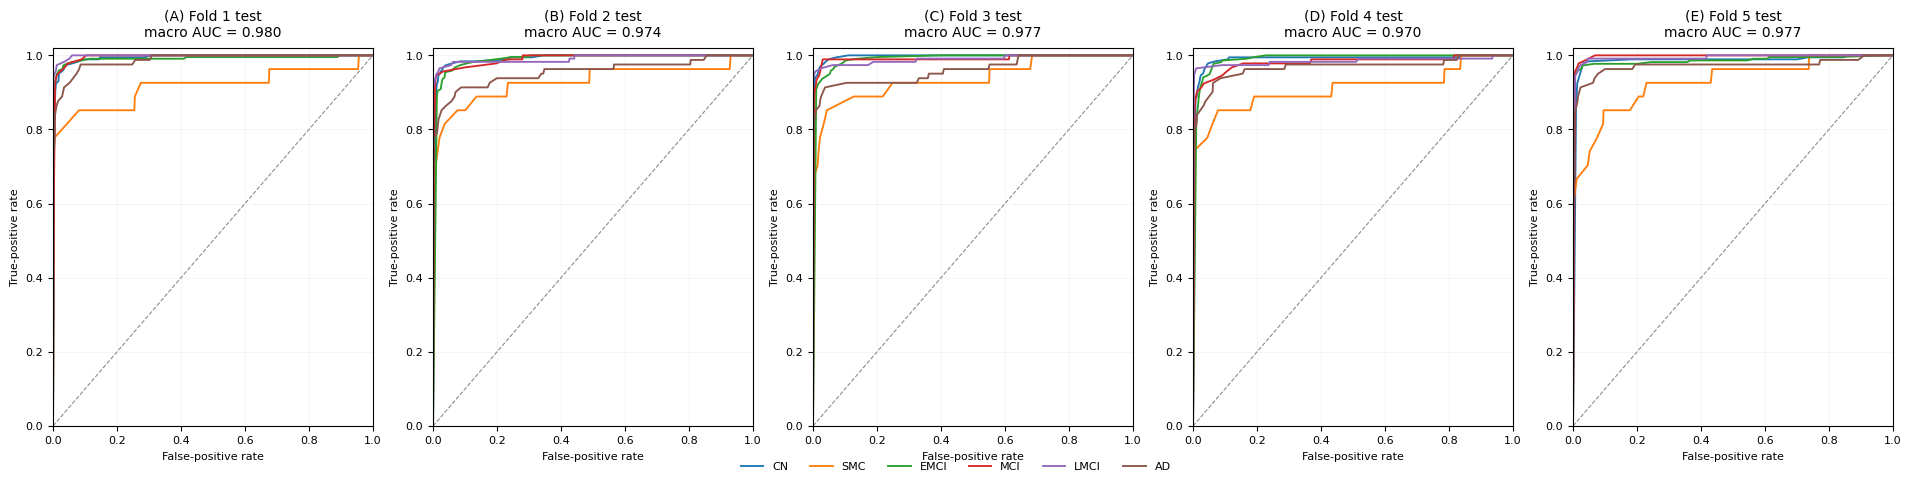

In [5]:
def proposed_roc_curves(fold):
    data = fold_data['Proposed'][fold]
    y_true_ids = data['true_ids']
    curves = {}
    for idx, name in enumerate(SOURCE_CLASS_ORDER):
        fpr, tpr, _ = roc_curve((y_true_ids == idx).astype(int), data['probs'][:, idx])
        curves[name] = {'fpr': fpr, 'tpr': tpr, 'auc': auc(fpr, tpr)}
    return curves

def efficientnet_roc_curves(fold):
    path = path_for(MODEL_SPECS['EfficientNet-B0'], 'roc_template', fold)
    if not path.exists():
        return None
    df = pd.read_csv(path)
    required = {'class', 'fpr', 'tpr'}
    if not required.issubset(df.columns):
        raise ValueError(f'EfficientNet fold {fold} ROC file lacks {required - set(df.columns)}')
    curves = {}
    for name in SOURCE_CLASS_ORDER:
        part = df[df['class'].astype(str) == name].copy()
        if part.empty:
            raise ValueError(f'EfficientNet fold {fold} ROC file lacks class {name}')
        part = part.sort_values(['fpr', 'tpr']).drop_duplicates(['fpr'], keep='last')
        fpr, tpr = part['fpr'].to_numpy(float), part['tpr'].to_numpy(float)
        curves[name] = {'fpr': fpr, 'tpr': tpr, 'auc': auc(fpr, tpr)}
    return curves

def save_roc_panel(model_name, file_prefix, curve_loader):
    curves_by_fold = {fold: curve_loader(fold) for fold in FOLDS}
    if any(v is None for v in curves_by_fold.values()):
        print(f'{model_name}: exact ROC data are not available for all five folds; no ROC panel generated.')
        return False
    auc_rows = []
    fig, axes = plt.subplots(1, 5, figsize=(19.0, 4.6), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, fold in zip(axes, FOLDS):
        curves = curves_by_fold[fold]
        values = []
        for name in CLASS_NAMES:
            curve = curves[name]
            ax.plot(curve['fpr'], curve['tpr'], lw=1.35, color=CLASS_COLORS[name], label=name)
            values.append(curve['auc'])
            auc_rows.append({'fold': fold, 'class': name, 'auc': curve['auc']})
        ax.plot([0, 1], [0, 1], '--', color='0.55', lw=0.8)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.set_xlabel('False-positive rate', fontsize=8)
        ax.set_ylabel('True-positive rate', fontsize=8)
        ax.grid(alpha=0.18, linewidth=0.5)
        ax.set_title(f"({PANEL_LABELS[fold]}) Fold {fold} test\nmacro AUC = {np.mean(values):.3f}", fontsize=10, pad=8)
        ax.tick_params(labelsize=8)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.035), fontsize=8)
    png = OUTPUT_DIR / f'{file_prefix}_FiveFold_ROC_Test_Panels.png'
    pdf = OUTPUT_DIR / f'{file_prefix}_FiveFold_ROC_Test_Panels.pdf'
    fig.savefig(png, dpi=600, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    pd.DataFrame(auc_rows).to_csv(OUTPUT_DIR / f'{file_prefix}_Foldwise_ROC_AUC.csv', index=False)
    print('Saved:', png)
    print('Saved:', pdf)
    print('Saved:', OUTPUT_DIR / f'{file_prefix}_Foldwise_ROC_AUC.csv')
    display(fig)
    plt.close(fig)
    return True

proposed_roc_panel = save_roc_panel('Proposed', 'Proposed', proposed_roc_curves)
efficientnet_roc_panel = save_roc_panel('EfficientNet-B0', 'EfficientNetB0', efficientnet_roc_curves)

In [6]:
def classwise_recall_table(model_name, file_prefix):
    rows = []
    for class_name in CLASS_NAMES:
        recalls = [fold_data[model_name][fold]['normalized'].loc[class_name, class_name] for fold in FOLDS]
        rows.append({'Class': class_name, **{f'Fold {fold} Recall': recalls[fold - 1] for fold in FOLDS}, 'Mean': np.mean(recalls), 'SD': np.std(recalls, ddof=1)})
    out = pd.DataFrame(rows)
    path = OUTPUT_DIR / f'{file_prefix}_Classwise_Recall_Across_Folds.csv'
    out.to_csv(path, index=False)
    print('Saved:', path)
    return out

proposed_recall = classwise_recall_table('Proposed', 'Proposed')
efficientnet_recall = classwise_recall_table('EfficientNet-B0', 'EfficientNetB0')
comparison = proposed_recall[['Class', 'Mean', 'SD']].rename(columns={'Mean': 'Proposed Recall Mean', 'SD': 'Proposed Recall SD'}).merge(efficientnet_recall[['Class', 'Mean', 'SD']].rename(columns={'Mean': 'EfficientNet Recall Mean', 'SD': 'EfficientNet Recall SD'}), on='Class')
comparison_path = OUTPUT_DIR / 'Proposed_vs_EfficientNet_Classwise_Recall.csv'
comparison.to_csv(comparison_path, index=False)
print('Saved:', comparison_path)

print('\nSUPPLEMENTARY CONFUSION MATRIX AND ROC ANALYSIS COMPLETE')
print('\nProposed:')
print('- exact folds available: 5/5')
print('- raw panel generated: YES')
print('- normalized panel generated: YES')
print('- ROC panel generated:', 'YES' if proposed_roc_panel else 'NO')
print('\nEfficientNet-B0:')
print('- exact folds available: 5/5')
print('- raw panel generated: YES')
print('- normalized panel generated: YES')
print('- ROC panel generated:', 'YES' if efficientnet_roc_panel else 'NO')
print('\nNo models were loaded.')
print('No inference was performed.')
print('No existing result files were modified.')
print('\nNewly generated files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.resolve())

Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_Classwise_Recall_Across_Folds.csv
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/EfficientNetB0_Classwise_Recall_Across_Folds.csv
Saved: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/Results/Analysis/Supplementary_Confusion_Matrices/Proposed_vs_EfficientNet_Classwise_Recall.csv

SUPPLEMENTARY CONFUSION MATRIX AND ROC ANALYSIS COMPLETE

Proposed:
- exact folds available: 5/5
- raw panel generated: YES
- normalized panel generated: YES
- ROC panel generated: YES

EfficientNet-B0:
- exact folds available: 5/5
- raw panel generated: YES
- normalized panel generated: YES
- ROC panel generated: YES

No models were loaded.
No inference was performed.
No existing result files were modified.

Newly generated files:
/media/faiz